In [1]:
# Install only if required
!pip install librosa xgboost

Defaulting to user installation because normal site-packages is not writeable


In [2]:
## Importing Libraries

import pandas as pd
import numpy as np
import os
import sys

import matplotlib.pyplot as plt
import seaborn as sns

import librosa
import librosa.display

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier

from IPython.display import display ,Audio

In [3]:
import warnings

warnings.filterwarnings('ignore')



In [4]:
datasetPath =('C:/Users/hande/Speech Emotion Recognition/RAVDESS Emotional')

In [5]:
dirList = os.listdir(datasetPath)

In [6]:
emotions = []
path =[]

In [7]:
for dirName in dirList:
    if dirName == ".DS_Store":
        continue

    fname = os.listdir(os.path.join(datasetPath, dirName))

    for name in fname:
        part = name.split('.')[0].split('-')[2]

        emotions.append(int(part))
        path.append(os.path.join(datasetPath, dirName, name))

IndexError: list index out of range

In [ ]:
emotions[:3]

In [ ]:
path[:3]

In [8]:
dataframe = pd.DataFrame(emotions,columns=['Emotions'])

In [9]:
dataframe =dataframe.replace({1:'neutral',2:'neutral',3:'happy',4:'sad',5:'angry',6:'fear',7:'disgust',8:'superise'})

In [10]:
dataframe ['Path']=path

In [11]:
dataframe.head()

,Emotions,Path
0,neutral,C:/Users/hande/Speech Emotion Recognition/RAVD...
1,neutral,C:/Users/hande/Speech Emotion Recognition/RAVD...
2,neutral,C:/Users/hande/Speech Emotion Recognition/RAVD...
3,neutral,C:/Users/hande/Speech Emotion Recognition/RAVD...
4,neutral,C:/Users/hande/Speech Emotion Recognition/RAVD...


In [12]:
dataframe.shape

(1440, 2)

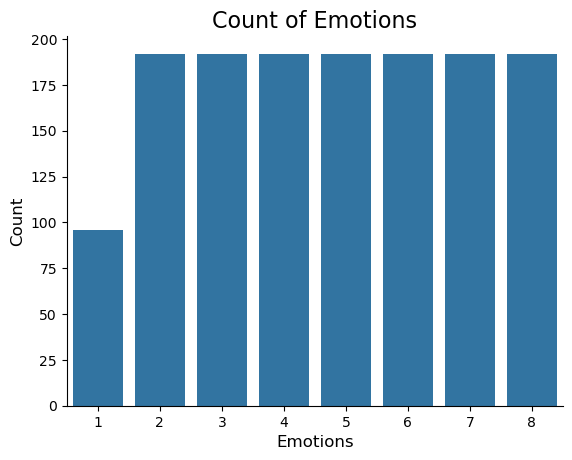

In [13]:
# Data Visualisation
plt.title('Count of Emotions', size=16)
sns.countplot(data=dataframe, x=emotions)
plt.ylabel('Count', size=12)
plt.xlabel('Emotions', size=12)
sns.despine(top=True,right=True,left=False,bottom=False)
plt.show()

In [14]:
%pip install --upgrade numba librosa

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [15]:
def create_waveplot(data,sr,e):
    plt.figure(figsize=(10,3))
    plt.title('Waveplot for audio with {} emotion'.format(e),size=15)
    librosa.display.waveshow(data,sr=sr)
    plt.show()

In [16]:
def create_spectrogram(data, sr, e):
    X = librosa.stft(data)
    Xdb = librosa.amplitude_to_db(abs(X), ref=np.max)

    plt.figure(figsize=(12, 3))
    plt.title("Spectrogram for audio with {} emotion".format(e), size=15)

    librosa.display.specshow(
        Xdb,
        sr=sr,
        x_axis='time',
        y_axis='hz'
    )

    plt.colorbar()
    plt.show()

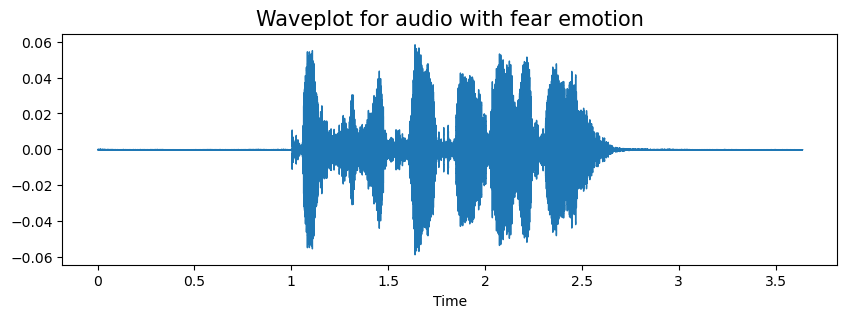

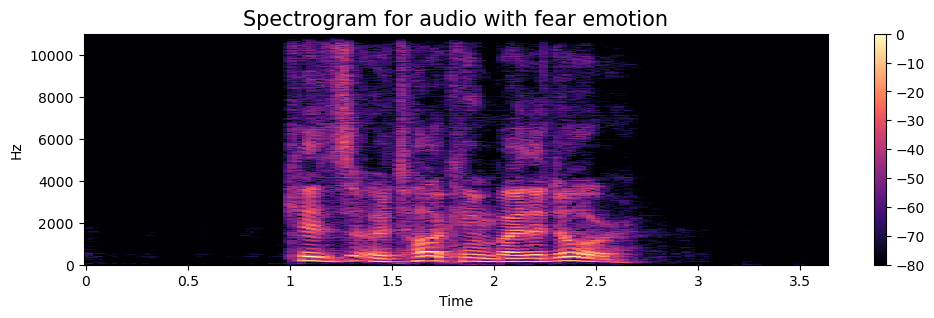

In [17]:
emotion ="fear"
fearPath= np.array(dataframe.Path[dataframe.Emotions==emotion])[1]
data, sampling_rate = librosa.load(fearPath)

create_waveplot(data,sampling_rate,emotion)
create_spectrogram(data,sampling_rate,emotion)

In [18]:
fearPath

'C:/Users/hande/Speech Emotion Recognition/RAVDESS Emotional\\Actor_01\\03-01-06-01-01-02-01.wav'

In [19]:
sampling_rate

22050

In [20]:
data

array([ 9.3495757e-05,  1.6403565e-04,  1.1930163e-04, ...,
        1.6012858e-11, -1.1257498e-11,  0.0000000e+00],
      shape=(80196,), dtype=float32)

In [21]:
Audio(fearPath)

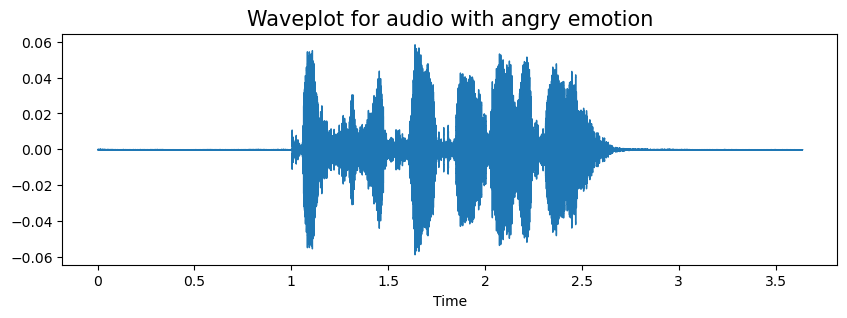

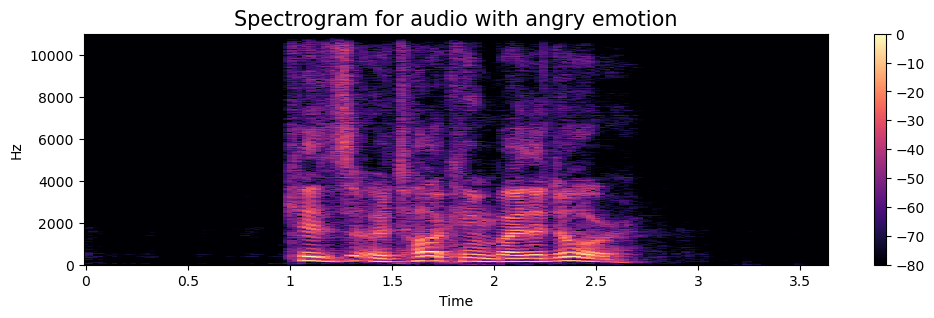

In [22]:
emotion ="angry"
angryPath= np.array(dataframe.Path[dataframe.Emotions==emotion])[1]
data, sampling_rate = librosa.load(fearPath)

create_waveplot(data,sampling_rate,emotion)
create_spectrogram(data,sampling_rate,emotion)

In [23]:
Audio(angryPath)

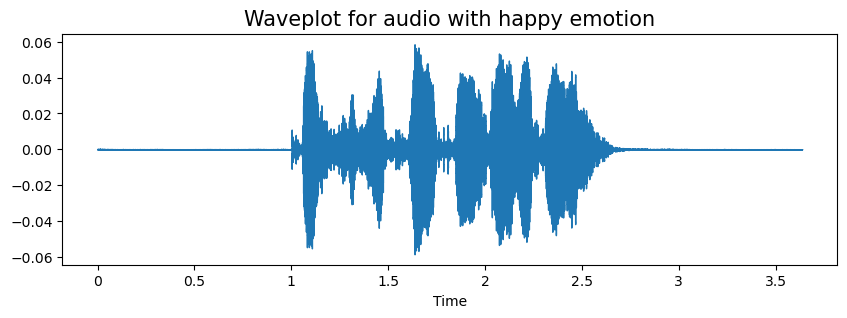

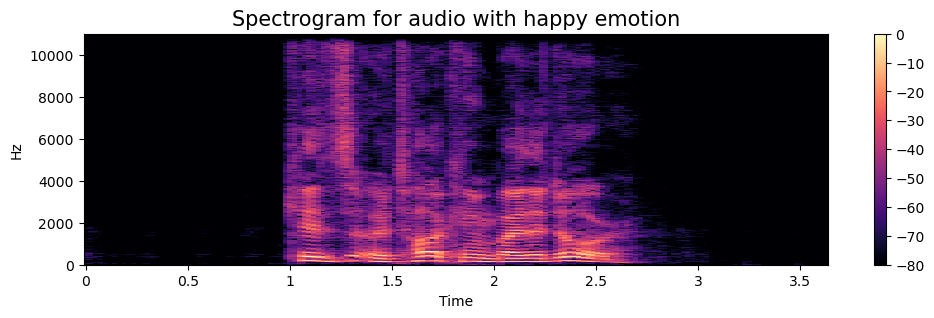

In [24]:
emotion ="happy"
happyPath= np.array(dataframe.Path[dataframe.Emotions==emotion])[1]
data, sampling_rate = librosa.load(fearPath)

create_waveplot(data,sampling_rate,emotion)
create_spectrogram(data,sampling_rate,emotion)

In [25]:
Audio(happyPath)

In [26]:
!pip install resampy
!python -m pip install resampy

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


In [27]:

# Emotion - Angry

path = np.array(dataframe.Path[dataframe.Emotions == 'angry'])[1]

X, sample_rate = librosa.load(
    path,
    res_type='kaiser_fast',
    duration=2.5,
    sr=22050*2,
    offset=0.5
)

angry = librosa.feature.mfcc(
    y=X,
    sr=sample_rate,
    n_mfcc=13
)

angry = np.mean(librosa.feature.mfcc(y=X,sr=sample_rate,n_mfcc=13),axis=0)


# Emotion - Happy

path = np.array(dataframe.Path[dataframe.Emotions == 'happy'])[1]

X, sample_rate = librosa.load(
    path,
    res_type='kaiser_fast',
    duration=2.5,
    sr=22050*2,
    offset=0.5
)

happy = librosa.feature.mfcc(
    y=X,
    sr=sample_rate,
    n_mfcc=13
)

happy = np.mean(librosa.feature.mfcc(y=X,sr=sample_rate,n_mfcc=13),axis=0)





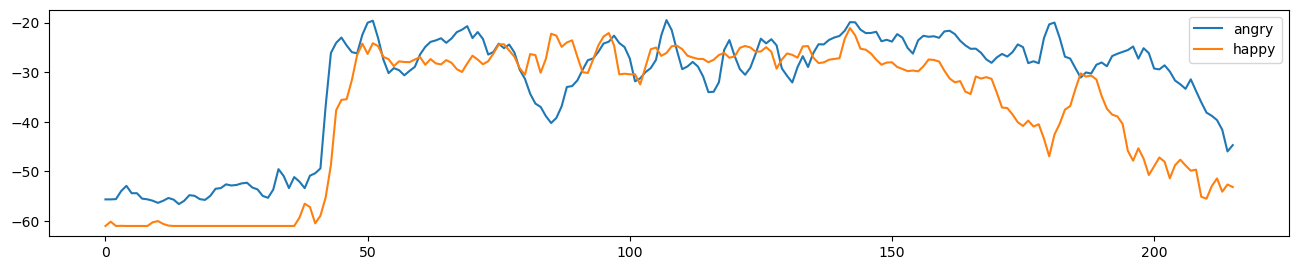

In [28]:
# plot the two audio was togther
plt.figure(figsize=(16,10))
plt.subplot(3,1,1)
plt.plot(angry,label='angry')
plt.plot(happy,label='happy')
plt.legend()
plt.show()

In [29]:
# data Augmentation

def noise(data):
    noise_amp= 0.035*np.random.uniform()*np.amax(data)
    data=data+noise_amp*np.random.normal(size=data.shape[0])
    return data

In [30]:
def stretch(data, rate=0.8):
    return librosa.effects.time_stretch(y=data, rate=rate)


In [31]:
def shift(data):
    shift_range= int(np.random.uniform(low=5,high=5)*1000)
    return np.roll(data,shift_range)

In [32]:

def pitch(data, sampling_rate, pitch_factor=0.7):
    return librosa.effects.pitch_shift(
        y=data,
        sr=sampling_rate,
        n_steps=pitch_factor
    )



In [33]:
# adding noise,pitch
path=np.array(dataframe.Path)[1]
data,sample_rate=librosa.load(path)

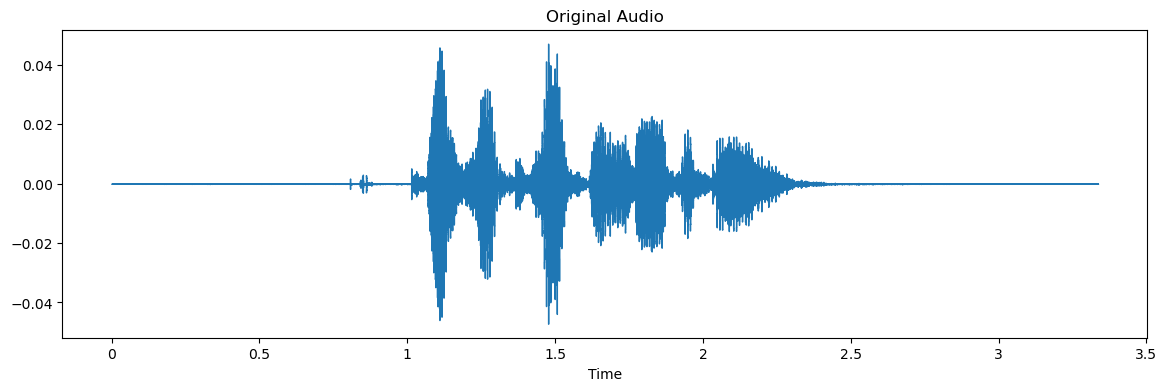

In [34]:
#Original Audio
plt.figure(figsize=(14,4))
librosa.display.waveshow(y=data,sr=sample_rate)
plt.title("Original Audio")
Audio(path)
def pitch(data, sampling_rate, pitch_factor=0.7):
    return librosa.effects.pitch_shift(
        y=data,
        sr=sampling_rate,
        n_steps=pitch_factor
    )



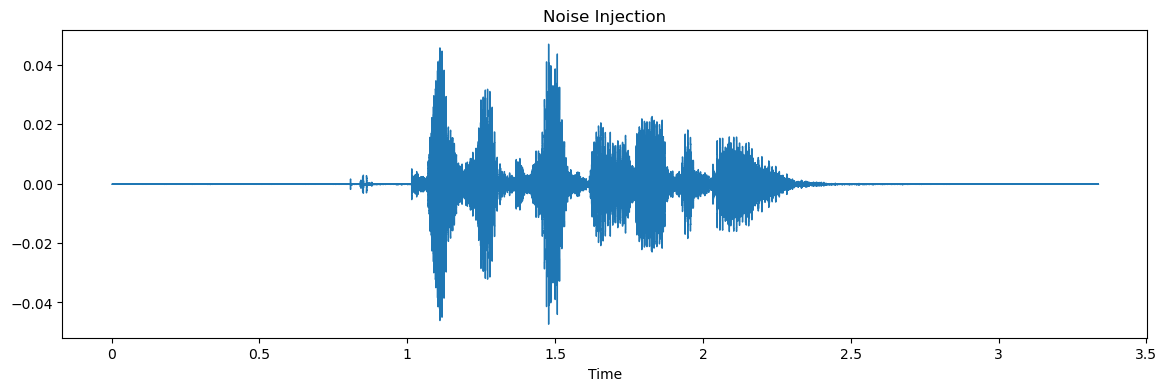

In [35]:
x=noise(data)
plt.figure(figsize=(14,4))
librosa.display.waveshow(y=data,sr=sample_rate)
plt.title("Noise Injection")
Audio(x,rate=sample_rate)

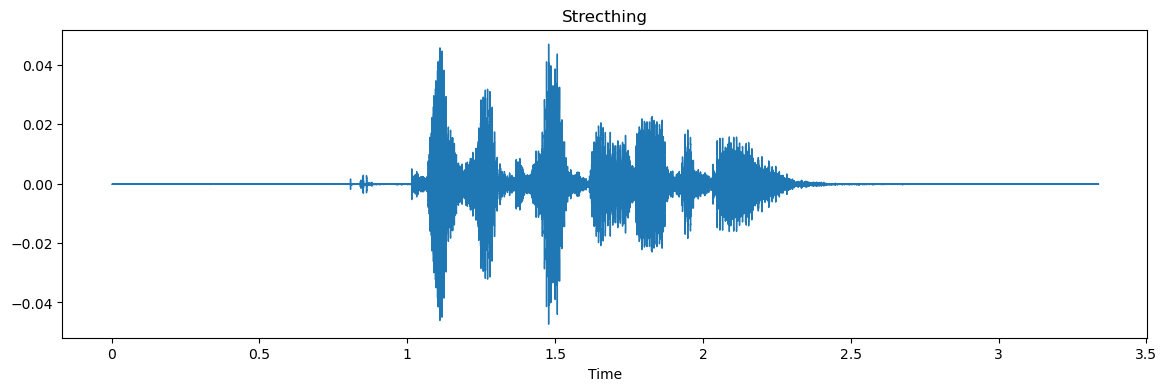

In [36]:
x=stretch(data)
plt.figure(figsize=(14,4))
librosa.display.waveshow(y=data,sr=sample_rate)
plt.title("Strecthing")
Audio(x,rate=sample_rate)

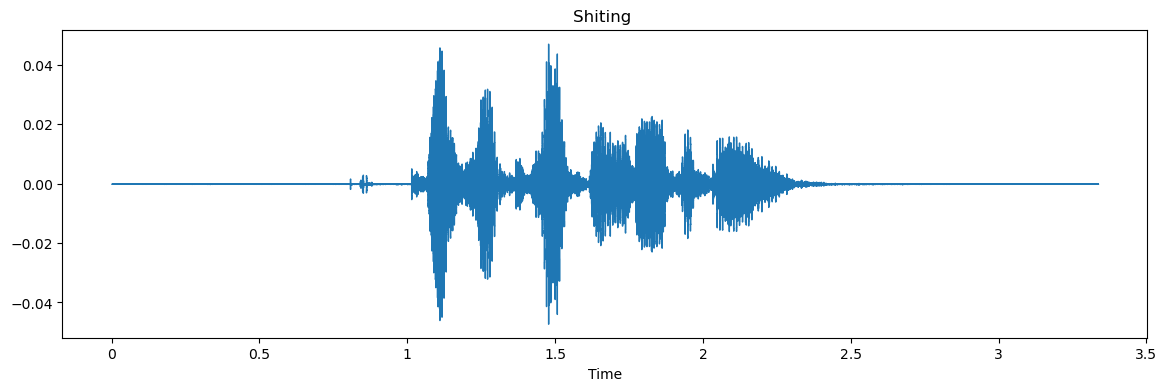

In [37]:
x=shift(data)
plt.figure(figsize=(14,4))
librosa.display.waveshow(y=data,sr=sample_rate)
plt.title("Shiting ")
Audio(x,rate=sample_rate)

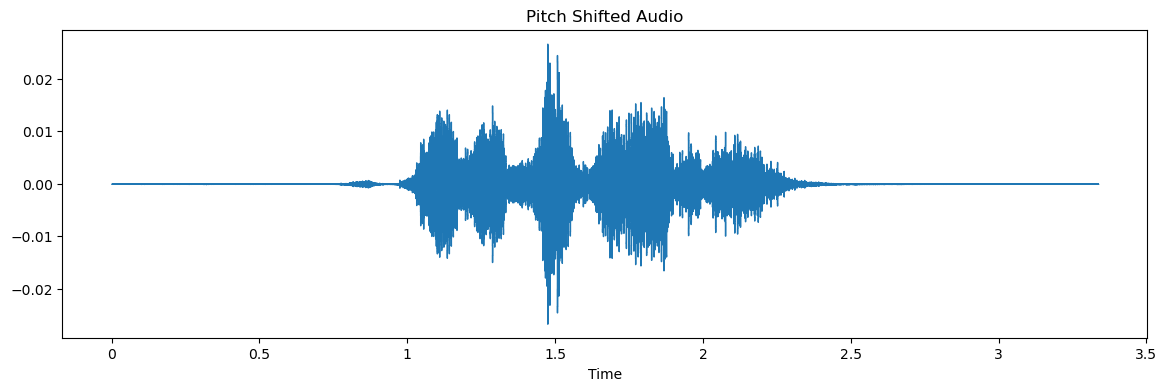

In [38]:


x = pitch(data, sample_rate)

plt.figure(figsize=(14, 4))
librosa.display.waveshow(y=x, sr=sample_rate)
plt.title("Pitch Shifted Audio")
plt.show()

display(Audio(x, rate=sample_rate))



In [39]:

# Feature Extraction
def extract_features(data):
    # Zero Crossing Rate (ZCR)
    result = np.array([])

    zcr = np.mean(
        librosa.feature.zero_crossing_rate(y=data).T,
        axis=0
    )
    result = np.hstack((result, zcr))

    # Chroma STFT
    stft = np.abs(librosa.stft(data))

    chroma_stft = np.mean(
        librosa.feature.chroma_stft(S=stft, sr=sample_rate).T,
        axis=0
    )
    result = np.hstack((result, chroma_stft))

    # MFCC
    mfcc = np.mean(
        librosa.feature.mfcc(y=data, sr=sample_rate).T,
        axis=0
    )
    result = np.hstack((result, mfcc))

    # Root Mean Square (RMS)
    rms = np.mean(
        librosa.feature.rms(y=data).T,
        axis=0
    )
    result = np.hstack((result, rms))

    # Mel Spectrogram
    mel = np.mean(
        librosa.feature.melspectrogram(
            y=data,
            sr=sample_rate
        ).T,
        axis=0
    )
    result = np.hstack((result, mel))

    return result



In [40]:

def get_features(path):
    data, sample_rate = librosa.load(path, duration=2.5, offset=0.6)

    # Extract features from original audio
    result = np.array(extract_features(data))

    # Noise augmentation
    noise_data = noise(data)
    result = np.vstack((result, extract_features(noise_data)))

    # Stretching and pitch augmentation
    data_stretch_pitch = pitch(stretch(data), sample_rate)
    result = np.vstack((result, extract_features(data_stretch_pitch)))

    return result



In [41]:
# Extracting and processing features from the dataset

X, Y = [], []

for path, emotion in zip(dataframe.Path, dataframe.Emotions):
    features = get_features(path)

    for ele in features:
        X.append(ele)
        Y.append(emotion)

In [42]:
len(X),len(Y),dataframe.shape

(4320, 4320, (1440, 2))

In [43]:
x_train,x_test,y_train,y_test =train_test_split(X,Y,test_size=0.1,random_state=3,shuffle=True)
len(x_train),len(y_train),len(x_test),len(y_test)

(3888, 3888, 432, 432)

In [44]:

# Scaling features
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit and transform training data
x_train = scaler.fit_transform(x_train)

# Transform test data
x_test = scaler.transform(x_test)



In [45]:
print("Total number of trainning sample:",x_train.shape[0])
print("Total number of testing sample:",x_test.shape[0])
print("Feature Extraction:",x_train.shape[1])

Total number of trainning sample: 3888
Total number of testing sample: 432
Feature Extraction: 162


In [46]:

from sklearn.metrics import accuracy_score

def modelProcess(trainX, testX, trainY, testY, model, name):
    print("Processing {} model".format(name))
    print("Training the model")

    model.fit(trainX, trainY)

    print("Evaluating the model")
    predY = model.predict(testX)

    accuracy = accuracy_score(y_true=testY, y_pred=predY) * 100

    print("Accuracy of {}: {:.2f}%".format(name, accuracy))
    print("-------" * 8)
    print()

    return accuracy, predY



In [47]:
from sklearn.ensemble import AdaBoostClassifier

In [48]:

# Import required libraries
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import AdaBoostClassifier
from xgboost import XGBClassifier

# Define models
logistic = LogisticRegression(max_iter=1000)
svm = SVC()
adaboost = AdaBoostClassifier(random_state=42)
xgboost = XGBClassifier(
    n_estimators=100,
    random_state=42,
    eval_metric="mlogloss"
)



In [49]:
#modelling process for Logidtic Regression
logisticAcc,y_predLogistic =modelProcess(x_train,x_test,y_train,y_test,logistic,"Logistic Regression")

Processing Logistic Regression model
Training the model
Evaluating the model
Accuracy of Logistic Regression: 57.41%
--------------------------------------------------------



In [50]:
#modelling process for SVM
svmAcc,y_predSVM =modelProcess(x_train,x_test,y_train,y_test,svm,"SVM")

Processing SVM model
Training the model
Evaluating the model
Accuracy of SVM: 59.95%
--------------------------------------------------------



In [51]:
#modelling process for Adaboost
adaboostAcc,y_predadaboost =modelProcess(x_train,x_test,y_train,y_test,adaboost,"Adaboost")

Processing Adaboost model
Training the model
Evaluating the model
Accuracy of Adaboost: 39.12%
--------------------------------------------------------



In [52]:

from sklearn.preprocessing import LabelEncoder

# Encode emotion labels
encoder = LabelEncoder()

y_train_encoded = encoder.fit_transform(y_train)
y_test_encoded = encoder.transform(y_test)

print("Emotion classes:", encoder.classes_)
print("Encoded labels:", sorted(set(y_train_encoded)))



Emotion classes: ['angry' 'disgust' 'fear' 'happy' 'neutral' 'sad' 'superise']
Encoded labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


In [53]:
from xgboost import XGBClassifier

# Define XGBoost model
xgboost = XGBClassifier(
    n_estimators=100,
    random_state=42,
    eval_metric="mlogloss"
)

# Train and evaluate
xgboostAcc, y_predxgboost = modelProcess(
    x_train,
    x_test,
    y_train_encoded,
    y_test_encoded,
    xgboost,
    "XGBoost"
)

Processing XGBoost model
Training the model
Evaluating the model
Accuracy of XGBoost: 79.86%
--------------------------------------------------------



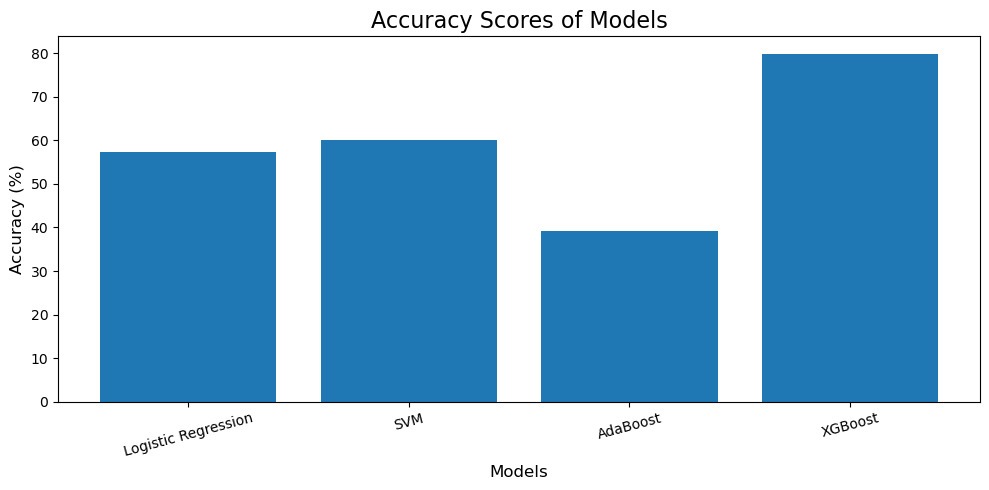

In [54]:
# Visualizing results
plt.figure(figsize=(10, 5))

plt.title('Accuracy Scores of Models', size=16)

scores = [logisticAcc, svmAcc, adaboostAcc, xgboostAcc]

modelNames = ['Logistic Regression', 'SVM', 'AdaBoost', 'XGBoost']

plt.bar(modelNames, scores)

plt.ylabel('Accuracy (%)', size=12)
plt.xlabel('Models', size=12)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

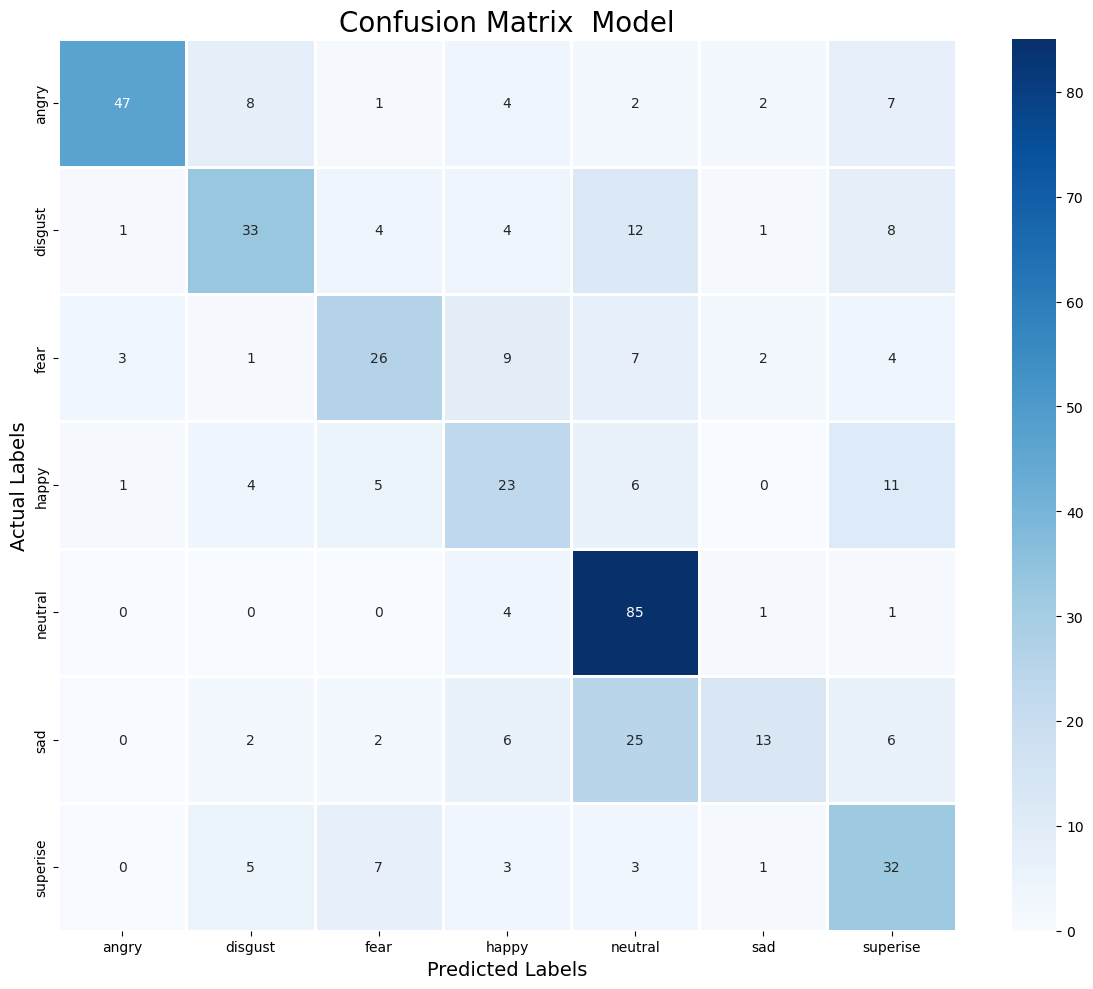

In [55]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_predSVM)

plt.figure(figsize=(12, 10))

cm = pd.DataFrame(
    cm,
    index=encoder.classes_,
    columns=encoder.classes_
)

sns.heatmap(
    cm,
    linecolor='white',
    cmap='Blues',
    linewidth=1,
    annot=True,
    fmt='d'
)

plt.title('Confusion Matrix  Model', size=20)
plt.xlabel('Predicted Labels', size=14)
plt.ylabel('Actual Labels', size=14)
plt.tight_layout()
plt.show()

In [56]:
print("classification Report")
print(classification_report(y_test,y_predSVM))

classification Report
              precision    recall  f1-score   support

       angry       0.90      0.66      0.76        71
     disgust       0.62      0.52      0.57        63
        fear       0.58      0.50      0.54        52
       happy       0.43      0.46      0.45        50
     neutral       0.61      0.93      0.74        91
         sad       0.65      0.24      0.35        54
    superise       0.46      0.63      0.53        51

    accuracy                           0.60       432
   macro avg       0.61      0.56      0.56       432
weighted avg       0.62      0.60      0.59       432



In [60]:
import pickle

with open('xtrain.pkl', 'wb') as f:
    pickle.dump(x_train, f)

with open('xtest.pkl', 'wb') as f:
    pickle.dump(x_test, f)

with open('ytrain.pkl', 'wb') as f:
    pickle.dump(y_train, f)

with open('ytest.pkl', 'wb') as f:
    pickle.dump(y_test, f)
    

In [61]:
## Importing Libraries

import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM,Dense,Dropout,BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

import matplotlib.pyplot as plt
import seaborn as sns


In [65]:

import os

files = ['xtrain.pkl', 'xtest.pkl', 'ytrain.pkl', 'ytest.pkl']

for file in files:
    if os.path.exists(file):
        print(f"{file}: {os.path.getsize(file)} bytes")
    else:
        print(f"{file}: File not found")


xtrain.pkl: 5039011 bytes
xtest.pkl: 0 bytes
ytrain.pkl: 7844 bytes
ytest.pkl: 926 bytes


In [66]:
import pickle

with open('xtrain.pkl', 'rb') as f:
   x_train =pickle.load(f)
#with open('xtest.pkl', 'rb') as f:
  # x_test =pickle.load(f)

with open('ytrain.pkl', 'rb') as f:
   y_train =pickle.load(f)

with open('ytest.pkl', 'rb') as f:
   y_test =pickle.load(f)
    

In [67]:
print("Total number of traing sample :",x_train.shape[0])
print("Total number of testing sample :",x_test.shape[0])
x_train.shape

Total number of traing sample : 3888
Total number of testing sample : 432


(3888, 162)

In [68]:
#verify data shapes
print(f"x_train shape :{x_train.shape}")
print(f"x_test shape :{x_test.shape}")
print(f"y_train shape :{len(y_train)}")
print(f"y_test shape :{len(y_test)}")

x_train shape :(3888, 162)
x_test shape :(432, 162)
y_train shape :3888
y_test shape :432


In [71]:
# Get number clasess
num_classes =len(np.unique(y_train))
print(f"Number of classes : {num_classes}")

Number of classes : 7


In [101]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()

In [74]:
Y_train =le.fit_transform(y_train)
Y_test =le.fit_transform(y_test)

In [75]:
# convert Labels to one -hot encodeing
y_train_encoded =to_categorical(Y_train,num_classes=num_classes)
y_test_encoded =to_categorical(Y_test,num_classes=num_classes)

In [76]:
# Reshape data for LSTM (samples, timesteps, features)
def prepare_data(X, timesteps=5):
    X_reshaped = []

    for i in range(len(X) - timesteps + 1):
        X_reshaped.append(X[i:i + timesteps])

    return np.array(X_reshaped)



In [77]:

# Prepare data for LSTM
timesteps = 5  # You can adjust this

X_train_reshaped = prepare_data(x_train, timesteps)
X_test_reshaped = prepare_data(x_test, timesteps)

y_train_reshaped = y_train_encoded[timesteps - 1:]
y_test_reshaped = y_test_encoded[timesteps - 1:]



In [78]:
print(f"Reshaped X_train{X_train_reshaped.shape}")
print(f"Reshaped X_test{X_test_reshaped.shape}")
print(f"Reshaped y_train{y_train_reshaped.shape}")
print(f"Reshaped y_test{y_test_reshaped.shape}")

Reshaped X_train(3884, 5, 162)
Reshaped X_test(428, 5, 162)
Reshaped y_train(3884, 7)
Reshaped y_test(428, 7)


In [79]:
# Build the LSTM model
model = Sequential([
    LSTM(128, input_shape=(timesteps, 162), return_sequences=True),
    BatchNormalization(),
    Dropout(0.3),

    LSTM(64),
    BatchNormalization(),
    Dropout(0.3),

    Dense(32, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),

    Dense(num_classes, activation='softmax')
])

# Compile the model
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Display model architecture
model.summary()



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 5, 128)         │       148,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 5, 128)         │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 5, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 201,607 (787.53 KB)

 Trainable params: 201,159 (785.78 KB)

 Non-trainable params: 448 (1.75 KB)

In [80]:
# Early Stopping
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

# Reduce Learning Rate on Plateau
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=5,
    min_lr=0.00001
)


In [81]:
# Train the model
history = model.fit(
    X_train_reshaped,
    y_train_reshaped,
    validation_data=(X_test_reshaped, y_test_reshaped),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)



Epoch 1/100
122/122 ━━━━━━━━━━━━━━━━━━━━ 13s 27ms/step - accuracy: 0.1686 - loss: 2.4172 - val_accuracy: 0.2150 - val_loss: 1.9426 - learning_rate: 0.0010
Epoch 2/100
122/122 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.2165 - loss: 2.0953 - val_accuracy: 0.2710 - val_loss: 1.8747 - learning_rate: 0.0010
Epoch 3/100
122/122 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.2652 - loss: 1.9182 - val_accuracy: 0.3271 - val_loss: 1.7736 - learning_rate: 0.0010
Epoch 4/100
122/122 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.3048 - loss: 1.8090 - val_accuracy: 0.3458 - val_loss: 1.6803 - learning_rate: 0.0010
Epoch 5/100
122/122 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.3427 - loss: 1.6980 - val_accuracy: 0.3762 - val_loss: 1.6170 - learning_rate: 0.0010
Epoch 6/100
122/122 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.3728 - loss: 1.6341 - val_accuracy: 0.3832 - val_loss: 1.5708 - learning_rate: 0.0010
Epoch 7/100
122/122 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.4001 - 

In [82]:

# Evaluate the model
test_loss, test_accuracy = model.evaluate(
    X_test_reshaped,
    y_test_reshaped,
    verbose=0
)

print(f'Test Loss: {test_loss:.4f}')
print(f'Test Accuracy: {test_accuracy:.4f}')



Test Loss: 1.2030
Test Accuracy: 0.6121


14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.69      0.77        71
           1       0.65      0.42      0.51        62
           2       0.60      0.56      0.58        52
           3       0.52      0.49      0.51        49
           4       0.64      0.84      0.73        91
           5       0.55      0.43      0.48        53
           6       0.45      0.70      0.55        50

    accuracy                           0.61       428
   macro avg       0.61      0.59      0.59       428
weighted avg       0.63      0.61      0.61       428



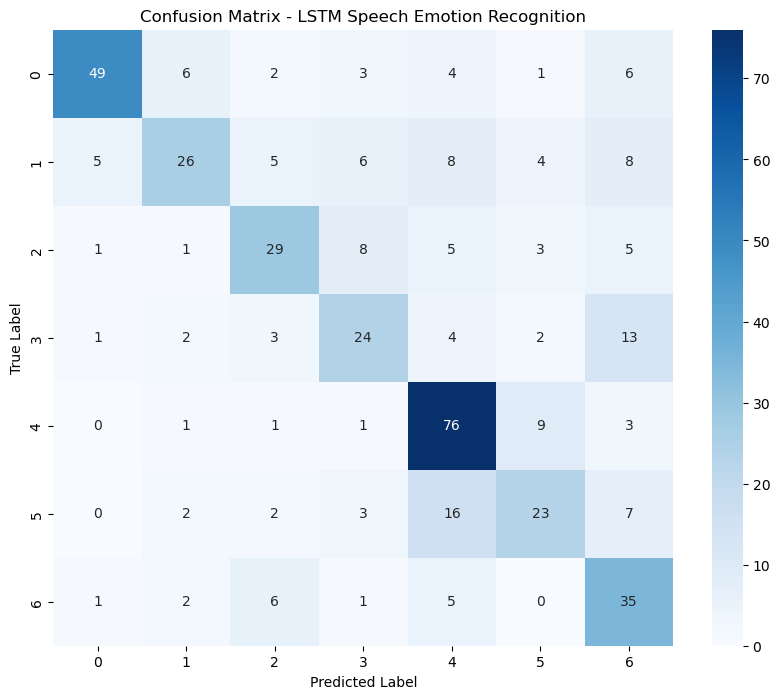

In [83]:
# Make predictions
predictions = model.predict(X_test_reshaped)

predicted_classes = np.argmax(predictions, axis=1)
true_classes = np.argmax(y_test_reshaped, axis=1)

# Print classification report
print("\nClassification Report:")
print(classification_report(true_classes, predicted_classes))

# Plot confusion matrix
cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title('Confusion Matrix - LSTM Speech Emotion Recognition')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()



In [84]:
import pickle

with open('xtrain.pkl', 'wb') as f:
    pickle.dump(x_train, f)

with open('xtest.pkl', 'wb') as f:
    pickle.dump(x_test, f)

with open('ytrain.pkl', 'wb') as f:
    pickle.dump(y_train, f)

with open('ytest.pkl', 'wb') as f:
    pickle.dump(y_test, f)
    

In [85]:
import pickle
svm.fit(x_train,y_train)
pickle.dump(svm,open("svmModel.pkl",'wb'))

In [86]:
moel =pickle.load(open("svmModel.pkl","rb"))

In [88]:
data, sampling_rate = librosa.load(
    r"C:\Users\hande\Speech Emotion Recognition\RAVDESS Emotional\Actor_07\03-01-02-02-02-02-07.wav",
    
)

In [89]:
Audio(data,rate=sampling_rate)

In [94]:

feature = get_features(
    r"C:\Users\hande\Speech Emotion Recognition\RAVDESS Emotional\Actor_07\03-01-02-02-02-02-07.wav"
)



ValueError: Exception encountered when calling Sequential.call().

[1mCannot take the length of shape with unknown rank.[0m

Arguments received by Sequential.call():
  • inputs=tf.Tensor(shape=<unknown>, dtype=float32)
  • training=False
  • mask=None
  • kwargs=<class 'inspect._empty'>

In [97]:

import numpy as np

# Convert features to NumPy array
feature = np.asarray(feature, dtype=np.float32)

# Pad the sequence to 5 timesteps
timesteps = 5

if feature.shape[0] < timesteps:
    padding = np.zeros((timesteps - feature.shape[0], feature.shape[1]))
    feature = np.vstack((feature, padding))

# Add batch dimension
feature_reshaped = np.expand_dims(feature, axis=0)

print("Input shape:", feature_reshaped.shape)



Input shape: (1, 5, 162)


In [99]:
# Make prediction
predictions = model.predict(feature_reshaped)

# Get predicted emotion class
predicted_class = np.argmax(predictions, axis=1)[0]

print("Predicted emotion class:", predicted_class)
print("Prediction probabilities:", predictions[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
Predicted emotion class: 4
Prediction probabilities: [7.6875725e-04 1.1694082e-03 5.3370530e-03 7.1235278e-05 9.9077320e-01
 1.7971329e-03 8.3280349e-05]


In [103]:
emotion_label = le.inverse_transform([predicted_class])[0]

print("Predicted Emotion:", emotion_label)

NotFittedError: This LabelEncoder instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.

In [104]:
model.predict(scaler.transfrom(feature))[0]

AttributeError: 'StandardScaler' object has no attribute 'transfrom'

In [ ]:
max(model.predict_proba(scaler.transfrom(feature))[0])